# Fire Intelligence · Inteligência Artificial & Machine Learning

**Global Solution FIAP 2026.2 · CitizenTech · Engenharia de Software (3º ano)**

Aluno: _Luiz Silva - RM560110_ <br> _Arthur Gomes - RM560771_<br>_Pedro Estevam - RM560642_<br> _Matheus Siroma - RM560248_· Repositório: _preencher link_

## Pergunta do modelo

> **Quantos focos de calor o satélite de referência do INPE deve detectar em cada célula da área de estudo no próximo mês, se o padrão histórico se repetir?**

O modelo é uma **regressão de contagem** (Poisson). Ele estima um número de detecções por célula de grade (~11 km) e por mês, a partir apenas do histórico de focos do INPE. A soma das células que cobrem um polígono dá a estimativa para a área escolhida no mapa do Fire Intelligence.

**Para quem é útil.** Brigadistas e gestores planejam escala de equipes, rondas e logística com semanas de antecedência. Saber quantas detecções a área costuma ter no próximo mês, e onde elas se concentram, ajuda nesse planejamento.

> **Posicionamento (igual ao do piloto).** A estimativa é **experimental e descritiva**. Ela não classifica risco, não define limiares, não indica áreas aptas ou seguras para queima e não substitui avaliação de campo, profissionais habilitados, licenças ou protocolos oficiais. Um foco de calor é uma detecção por satélite, não um incêndio nem uma área queimada.

### Roteiro (critérios da disciplina)

| Seção | Critério | Peso |
|---|---|---|
| 1 | Problema e dados | 2,0 |
| 2 | Preparação e análise | 2,0 |
| 3 | Modelo e treino | 3,0 |
| 4 | Avaliação com métrica | 2,0 |
| 5 | Integração na solução | 1,0 |

## 1. Problema e dados

**Fonte.** INPE, Programa Queimadas, Banco de Dados de Queimadas (BDQueimadas): <https://terrabrasilis.dpi.inpe.br/queimadas/bdqueimadas/>

**Download automático.** Se `dados/` estiver vazia, a célula de download abaixo:
1. busca os arquivos anuais do servidor de dados abertos do INPE (<https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/>), pasta do satélite de referência de Goiás ou do Brasil;
2. para o ano corrente, usa os arquivos mensais;
3. recorta a Chapada dos Veadeiros e grava **um único CSV pequeno** em `dados/`, com `dados/ORIGEM.txt` registrando data e arquivos usados.

O CSV gerado vai para o repositório. Quem rodar o notebook depois (inclusive o professor) não baixa nada.

O notebook mantém **apenas o satélite de referência** (AQUA_M-T). Misturar satélites quebra a série histórica, porque cada satélite detecta quantidades diferentes.

**Unidade de análise.** Célula de grade de 0,1° × 0,1° (cerca de 11 km) × mês.

**Variável alvo.** `focos` = número de detecções do satélite de referência na célula, no mês.

**Por que o modelo usa só o histórico de focos.** É a única fonte real já integrada no piloto. Chuva, umidade e cobertura da terra são próximos passos (seção 6).

In [1]:
# ---- Instalação das bibliotecas (rode uma vez; no Colab a maioria já vem instalada)
%pip install -q pandas numpy scikit-learn matplotlib shapely joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ---- Configuração ----------------------------------------------------------
import os, glob, json, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
SEMENTE = 42
np.random.seed(SEMENTE)

PASTA_DADOS = "dados"            # coloque aqui o(s) CSV(s) exportado(s) do BDQueimadas
PASTA_SAIDA = "saida"            # modelo, previsões e metadados gerados por este notebook
os.makedirs(PASTA_SAIDA, exist_ok=True)

# Retângulo da Chapada dos Veadeiros e entorno (graus decimais, WGS84)
LAT_MIN, LAT_MAX = -14.80, -13.50
LON_MIN, LON_MAX = -48.30, -46.90
TAMANHO_CELULA = 0.1             # graus (~11 km)

SATELITE_REFERENCIA = "AQUA_M-T" # confira o nome exato no seu arquivo
ANO_INICIO = 2012
INICIO_VALIDACAO = "2023-01-01"  # escolha do modelo
INICIO_TESTE = "2024-01-01"      # avaliação final (nunca usada no treino)

# Contingência: só use dados simulados se o download do INPE falhar.
# A versão entregue deve rodar com MODO_SIMULADO = False.
MODO_SIMULADO = os.environ.get("FI_MODO_SIMULADO", "0") == "1"
print("Modo simulado:", MODO_SIMULADO)

Modo simulado: False


In [3]:
# ---- Download automático do INPE (só roda se dados/ estiver vazia) ----------
# Baixa os arquivos anuais do servidor de dados abertos do INPE, recorta a Chapada
# e grava UM CSV pequeno em dados/. Façam commit desse CSV: depois disso ninguém
# (nem o professor) precisa baixar de novo.
import io, re, zipfile, urllib.request
from datetime import date
from functools import lru_cache

SERVIDOR = "https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv"
PASTAS_ANUAIS = [f"{SERVIDOR}/anual/EstadosBr_sat_ref/GO/", f"{SERVIDOR}/anual/Brasil_sat_ref/"]
PASTA_MENSAL = f"{SERVIDOR}/mensal/Brasil/"

COLUNAS = {"datahora": "data_hora", "data_hora_gmt": "data_hora", "data_hora": "data_hora", "data_pas": "data_hora",
           "latitude": "lat", "lat": "lat", "longitude": "lon", "lon": "lon", "satelite": "satelite",
           "municipio": "municipio", "estado": "estado", "bioma": "bioma", "frp": "frp"}


def _get(url, timeout=120):
    with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "fire-intelligence-fiap"}),
                                timeout=timeout) as r:
        return r.read()


@lru_cache(maxsize=None)
def listar(pasta):
    """Nomes de arquivo .zip/.csv que aparecem na listagem HTML da pasta."""
    try:
        html = _get(pasta, timeout=60).decode("utf-8", errors="ignore")
    except Exception as e:
        print(f"  não consegui listar {pasta}: {e}")
        return ()
    return tuple(sorted(set(re.findall(r'href="([^"?/]+\.(?:zip|csv))"', html))))


def recortar(conteudo: bytes, nome: str) -> pd.DataFrame:
    """Lê um CSV (ou o CSV dentro do ZIP) e mantém só os focos da área de estudo."""
    if nome.endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
            csvs = [n for n in z.namelist() if n.lower().endswith(".csv")]
            conteudo = z.read(csvs[0])
    partes = []
    for bloco in pd.read_csv(io.BytesIO(conteudo), sep=None, engine="python", chunksize=200_000):
        bloco.columns = [c.strip().lower() for c in bloco.columns]
        bloco = bloco.rename(columns={c: COLUNAS[c] for c in bloco.columns if c in COLUNAS})
        if "satelite" not in bloco and "_ref" in nome.lower():
            # arquivos das pastas *_sat_ref não têm a coluna: todos os focos são do satélite de referência
            bloco["satelite"] = SATELITE_REFERENCIA
        lat, lon = pd.to_numeric(bloco["lat"], errors="coerce"), pd.to_numeric(bloco["lon"], errors="coerce")
        partes.append(bloco[lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)])
    df = pd.concat(partes, ignore_index=True)
    manter = [c for c in ["data_hora", "lat", "lon", "satelite", "municipio", "estado", "bioma", "frp"] if c in df]
    return df[manter].assign(fonte_inpe=nome)


def arquivos_do_ano(ano, ano_atual):
    """Devolve [(url, nome)] para o ano: arquivo anual se existir, senão os mensais."""
    for pasta in PASTAS_ANUAIS:
        achados = [n for n in listar(pasta) if str(ano) in n]
        if achados:
            return [(pasta + achados[0], achados[0])]
    if ano == ano_atual or ano == ano_atual - 1:
        mensais = [n for n in listar(PASTA_MENSAL) if re.search(rf"{ano}(0[1-9]|1[0-2])", n)]
        return [(PASTA_MENSAL + n, n) for n in mensais]
    return []


def baixar(ano_inicio=2012, ano_fim=None, pasta_dados="dados"):
    ano_atual = date.today().year
    ano_fim = ano_fim or ano_atual
    os.makedirs(pasta_dados, exist_ok=True)
    tabelas, faltando = [], []
    for ano in range(ano_inicio, ano_fim + 1):
        arquivos = arquivos_do_ano(ano, ano_atual)
        if not arquivos:
            faltando.append(ano)
            print(f"{ano}: nenhum arquivo encontrado")
            continue
        for url, nome in arquivos:
            print(f"{ano}: baixando {nome} ...", end=" ", flush=True)
            try:
                df = recortar(_get(url, timeout=600), nome)
                tabelas.append(df)
                print(f"{len(df)} focos na área")
            except Exception as e:
                faltando.append(f"{ano} ({nome})")
                print(f"falhou: {e}")
    if not tabelas:
        raise RuntimeError("Nada foi baixado. Confira a conexão e os endereços em SERVIDOR.")

    final = pd.concat(tabelas, ignore_index=True).drop_duplicates(subset=["data_hora", "lat", "lon", "satelite"])
    saida = os.path.join(pasta_dados, f"focos_chapada_{ano_inicio}_{ano_fim}.csv")
    final.to_csv(saida, index=False)
    with open(os.path.join(pasta_dados, "ORIGEM.txt"), "w", encoding="utf-8") as f:
        f.write(f"Fonte: INPE, Programa Queimadas, servidor de dados abertos ({SERVIDOR})\n")
        f.write(f"Baixado em: {date.today().isoformat()} pelo notebook fire_intelligence_ml.ipynb\n")
        f.write(f"Recorte: lat {LAT_MIN} a {LAT_MAX}, lon {LON_MIN} a {LON_MAX}\n")
        f.write("Arquivos usados: " + ", ".join(sorted(final['fonte_inpe'].unique())) + "\n")
        if faltando:
            f.write("Não encontrados: " + ", ".join(map(str, faltando)) + "\n")
    print(f"\nGravado {saida} ({len(final)} focos). Anos faltando: {faltando or 'nenhum'}")
    return saida


if not glob.glob(os.path.join(PASTA_DADOS, "*.csv")) and not MODO_SIMULADO:
    baixar(ANO_INICIO, None, PASTA_DADOS)
else:
    print("dados/ já tem CSV (ou modo simulado): download pulado.")

2012: baixando focos_br_go_ref_2012.zip ... 1178 focos na área
2013: baixando focos_br_go_ref_2013.zip ... 310 focos na área
2014: baixando focos_br_go_ref_2014.zip ... 829 focos na área
2015: baixando focos_br_go_ref_2015.zip ... 1025 focos na área
2016: baixando focos_br_go_ref_2016.zip ... 612 focos na área
2017: baixando focos_br_go_ref_2017.zip ... 1000 focos na área
2018: baixando focos_br_go_ref_2018.zip ... 325 focos na área
2019: baixando focos_br_go_ref_2019.zip ... 807 focos na área
2020: baixando focos_br_go_ref_2020.zip ... 605 focos na área
2021: baixando focos_br_go_ref_2021.zip ... 724 focos na área
2022: baixando focos_br_go_ref_2022.zip ... 689 focos na área
2023: baixando focos_br_go_ref_2023.zip ... 437 focos na área
2024: baixando focos_br_go_ref_2024.zip ... 295 focos na área
2025: baixando focos_br_ref_2025.zip ... 683 focos na área
2026: baixando focos_mensal_br_202601.csv ... 74 focos na área
2026: baixando focos_mensal_br_202602.csv ... 37 focos na área
2026: 

In [4]:
# ---- Leitura dos arquivos do INPE -----------------------------------------
# Os exports do BDQueimadas já usaram nomes de coluna diferentes ao longo do tempo.
# Este mapa aceita as variações mais comuns e padroniza tudo.
MAPA_COLUNAS = {
    "datahora": "data_hora", "data_hora_gmt": "data_hora", "data_hora": "data_hora", "data_pas": "data_hora",
    "latitude": "lat", "lat": "lat",
    "longitude": "lon", "lon": "lon",
    "satelite": "satelite",
    "municipio": "municipio", "estado": "estado", "bioma": "bioma", "frp": "frp",
}

def ler_csv_inpe(caminho):
    for sep in [",", ";"]:
        df = pd.read_csv(caminho, sep=sep, low_memory=False)
        if df.shape[1] > 3:
            break
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={c: MAPA_COLUNAS[c] for c in df.columns if c in MAPA_COLUNAS})
    faltando = {"data_hora", "lat", "lon"} - set(df.columns)
    if faltando:
        raise ValueError(f"{caminho}: colunas não encontradas {faltando}. Colunas do arquivo: {list(df.columns)}")
    df["arquivo_origem"] = os.path.basename(caminho)
    # Os arquivos anuais das pastas *_sat_ref do INPE não trazem a coluna de satélite:
    # todos os focos deles já são do satélite de referência.
    if "satelite" not in df:
        df["satelite"] = np.nan
    df["satelite"] = df["satelite"].astype("object")   # coluna vazia vem como número; precisa aceitar texto
    origem = df["fonte_inpe"] if "fonte_inpe" in df else df["arquivo_origem"]
    sem_sat = df["satelite"].isna() & origem.astype(str).str.contains("_ref", case=False)
    df.loc[sem_sat, "satelite"] = SATELITE_REFERENCIA
    if sem_sat.any():
        print(f"{os.path.basename(caminho)}: {sem_sat.sum()} focos de arquivos *_sat_ref marcados como {SATELITE_REFERENCIA}")
    return df


def gerar_focos_simulados(inicio="2012-01-01", fim="2026-10-31"):
    # Gera focos fictícios com o MESMO formato do INPE, só para testar o código.
    # Sazonalidade de seca (jul-out), anos mais secos e 'manchas' espaciais recorrentes.
    rng = np.random.default_rng(SEMENTE)
    manchas = [(-14.10, -47.55, 0.15, 1.0), (-13.80, -47.45, 0.12, 0.7),
               (-14.55, -47.50, 0.20, 1.2), (-14.15, -48.05, 0.15, 0.6)]
    peso_mes = {1:.05, 2:.04, 3:.05, 4:.08, 5:.20, 6:.45, 7:.90, 8:1.6, 9:2.0, 10:1.0, 11:.25, 12:.08}
    linhas = []
    for mes in pd.period_range(inicio, fim, freq="M"):
        fator_ano = rng.lognormal(0, 0.35)
        for lat_c, lon_c, raio, peso in manchas:
            n = rng.poisson(6 * peso * peso_mes[mes.month] * fator_ano)
            lat = rng.normal(lat_c, raio, n); lon = rng.normal(lon_c, raio, n)
            dias = rng.integers(1, mes.days_in_month + 1, n)
            for la, lo, d in zip(lat, lon, dias):
                linhas.append({"data_hora": f"{mes.year}-{mes.month:02d}-{d:02d} 16:30:00",
                               "lat": la, "lon": lo, "satelite": SATELITE_REFERENCIA,
                               "municipio": "SIMULADO", "estado": "GOIÁS", "bioma": "Cerrado", "frp": rng.gamma(2, 15)})
    df = pd.DataFrame(linhas)
    df["arquivo_origem"] = "SIMULADO"
    return df


arquivos = sorted(glob.glob(os.path.join(PASTA_DADOS, "*.csv")))
if arquivos and not MODO_SIMULADO:
    brutos = pd.concat([ler_csv_inpe(a) for a in arquivos], ignore_index=True)
    ORIGEM_DADOS = "INPE, Programa Queimadas: " + ", ".join(os.path.basename(a) for a in arquivos)
elif MODO_SIMULADO:
    brutos = gerar_focos_simulados()
    ORIGEM_DADOS = "SIMULADO (contingência, não usar na entrega)"
else:
    raise FileNotFoundError(
        "Nenhum CSV em dados/. Baixe os focos do BDQueimadas (instruções na seção 1) "
        "ou rode com FI_MODO_SIMULADO=1 apenas para testar o código.")

print(ORIGEM_DADOS)
print("Registros brutos:", len(brutos))
brutos.head()

INPE, Programa Queimadas: focos_chapada_2012_2026.csv
Registros brutos: 19498


,data_hora,lat,lon,satelite,municipio,estado,bioma,fonte_inpe,frp,arquivo_origem
0,2012-02-05 16:44:00,-14.426,-47.961,AQUA_M-T,NIQUELÂNDIA,GOIÁS,Cerrado,focos_br_go_ref_2012.zip,NaN,focos_chapada_2012_2026.csv
1,2012-02-05 16:44:00,-14.416,-47.962,AQUA_M-T,NIQUELÂNDIA,GOIÁS,Cerrado,focos_br_go_ref_2012.zip,NaN,focos_chapada_2012_2026.csv
2,2012-03-13 17:03:00,-14.527,-47.395,AQUA_M-T,SÃO JOÃO D'ALIANÇA,GOIÁS,Cerrado,focos_br_go_ref_2012.zip,NaN,focos_chapada_2012_2026.csv
3,2012-03-13 17:03:00,-14.574,-47.100,AQUA_M-T,FORMOSA,GOIÁS,Cerrado,focos_br_go_ref_2012.zip,NaN,focos_chapada_2012_2026.csv
4,2012-03-29 17:03:00,-14.531,-47.635,AQUA_M-T,SÃO JOÃO D'ALIANÇA,GOIÁS,Cerrado,focos_br_go_ref_2012.zip,NaN,focos_chapada_2012_2026.csv


## 2. Preparação e análise

Passos de limpeza:
1. Converter data e coordenadas para os tipos certos e descartar linhas inválidas.
2. Manter só o satélite de referência e o período desde 2012.
3. Recortar pelo retângulo da área de estudo.
4. Remover duplicatas (o mesmo foco pode aparecer em dois arquivos baixados).
5. Descartar o último mês se ele estiver incompleto (download no meio do mês).

In [5]:
df = brutos.copy()
df["data_hora"] = pd.to_datetime(df["data_hora"], errors="coerce", format="mixed")
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
df["satelite"] = df["satelite"].astype(str).str.strip().str.upper()

relatorio = {"brutos": len(df)}
df = df.dropna(subset=["data_hora", "lat", "lon"]);               relatorio["validos"] = len(df)

print("Satélites no arquivo:", df["satelite"].value_counts().to_dict())
if SATELITE_REFERENCIA not in set(df["satelite"]):
    raise ValueError(f"Satélite {SATELITE_REFERENCIA} não está no arquivo. Ajuste SATELITE_REFERENCIA.")
df = df[df["satelite"] == SATELITE_REFERENCIA];                    relatorio["satelite_ref"] = len(df)
df = df[df["data_hora"].dt.year >= ANO_INICIO];                    relatorio["desde_ano_inicio"] = len(df)
df = df[df["lat"].between(LAT_MIN, LAT_MAX) & df["lon"].between(LON_MIN, LON_MAX)]
relatorio["na_area"] = len(df)
df = df.drop_duplicates(subset=["data_hora", "lat", "lon"]);      relatorio["sem_duplicatas"] = len(df)

# Último mês completo
data_max = df["data_hora"].max()
ultimo_mes = data_max.to_period("M")
if data_max.day < data_max.days_in_month:
    ultimo_mes = ultimo_mes - 1
df["mes"] = df["data_hora"].dt.to_period("M")
df = df[df["mes"] <= ultimo_mes];                                  relatorio["ate_ultimo_mes_completo"] = len(df)

print(pd.Series(relatorio, name="registros"))
print("Período analisado:", df["mes"].min(), "a", ultimo_mes)

Satélites no arquivo: {'AQUA_M-T': 9821, 'NOAA-20': 2843, 'NOAA-21': 2706, 'NPP-375': 1657, 'NPP-375D': 985, 'GOES-19': 963, 'METOP-B': 131, 'TERRA_M-T': 123, 'TERRA_M-M': 116, 'METOP-C': 114, 'AQUA_M-M': 35, 'MSG-03': 4}
brutos                     19498
validos                    19498
satelite_ref                9821
desde_ano_inicio            9821
na_area                     9821
sem_duplicatas              9821
ate_ultimo_mes_completo     9815
Name: registros, dtype: int64
Período analisado: 2012-01 a 2026-10


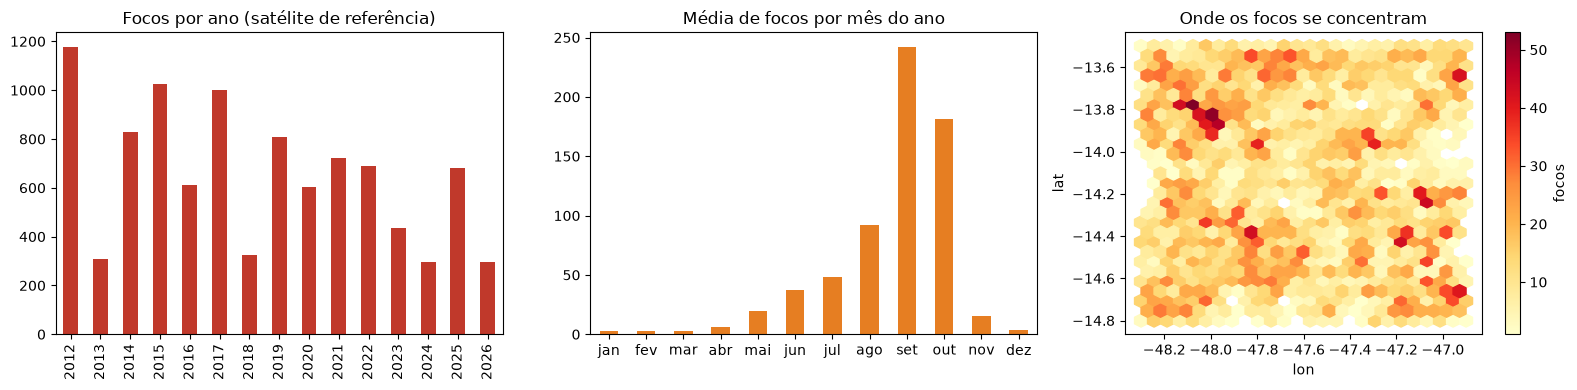

Leitura: a contagem é fortemente sazonal (estação seca) e se repete nas mesmas regiões.
Esses dois padrões, mês do ano e histórico da célula, são a base das variáveis do modelo.


In [6]:
# ---- Análise exploratória ---------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df.groupby(df["data_hora"].dt.year).size().plot(kind="bar", ax=ax[0], color="#c0392b")
ax[0].set_title("Focos por ano (satélite de referência)"); ax[0].set_xlabel("")

nomes_mes = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
anos = df["data_hora"].dt.year.nunique()
(df.groupby(df["data_hora"].dt.month).size().reindex(range(1, 13), fill_value=0) / anos).plot(
    kind="bar", ax=ax[1], color="#e67e22")
ax[1].set_xticklabels(nomes_mes, rotation=0)
ax[1].set_title("Média de focos por mês do ano"); ax[1].set_xlabel("")

hb = ax[2].hexbin(df["lon"], df["lat"], gridsize=25, cmap="YlOrRd", mincnt=1)
ax[2].set_title("Onde os focos se concentram"); ax[2].set_xlabel("lon"); ax[2].set_ylabel("lat")
fig.colorbar(hb, ax=ax[2], label="focos")
plt.tight_layout(); plt.show()

print("Leitura: a contagem é fortemente sazonal (estação seca) e se repete nas mesmas regiões.")
print("Esses dois padrões, mês do ano e histórico da célula, são a base das variáveis do modelo.")

In [7]:
# ---- Painel célula × mês (com zeros) ----------------------------------------
df["lin"] = np.floor((df["lat"] - LAT_MIN) / TAMANHO_CELULA).astype(int)
df["col"] = np.floor((df["lon"] - LON_MIN) / TAMANHO_CELULA).astype(int)

n_lin = int(np.ceil((LAT_MAX - LAT_MIN) / TAMANHO_CELULA))
n_col = int(np.ceil((LON_MAX - LON_MIN) / TAMANHO_CELULA))
meses = pd.period_range(df["mes"].min(), ultimo_mes, freq="M")

grade = pd.MultiIndex.from_product([range(n_lin), range(n_col), meses], names=["lin", "col", "mes"])
contagem = df.groupby(["lin", "col", "mes"]).size().rename("focos")
painel = contagem.reindex(grade, fill_value=0).reset_index()
painel["celula"] = painel["lin"].astype(str) + "_" + painel["col"].astype(str)
painel["lat_c"] = LAT_MIN + (painel["lin"] + 0.5) * TAMANHO_CELULA
painel["lon_c"] = LON_MIN + (painel["col"] + 0.5) * TAMANHO_CELULA

print(f"{n_lin * n_col} células × {len(meses)} meses = {len(painel)} linhas")
print(f"Linhas com zero focos: {(painel['focos'] == 0).mean():.1%}  (por isso usamos regressão de Poisson)")

196 células × 178 meses = 34888 linhas
Linhas com zero focos: 90.4%  (por isso usamos regressão de Poisson)


In [8]:
# ---- Variáveis explicativas (apenas informação disponível ANTES do mês previsto)
def montar_features(p):
    p = p.sort_values(["celula", "mes"]).copy()
    g = p.groupby("celula")["focos"]
    for k in [1, 2, 3, 12]:
        p[f"lag{k}"] = g.shift(k)
    p["soma_12m"] = g.transform(lambda s: s.shift(1).rolling(12).sum())
    # média histórica da célula para o mesmo mês do ano, só com anos anteriores
    p["mes_do_ano"] = p["mes"].dt.month
    p["media_hist_mes"] = (p.groupby(["celula", "mes_do_ano"])["focos"]
                             .transform(lambda s: s.shift(1).expanding().mean()))
    # vizinhança (8 células ao redor) e região inteira no mês anterior
    larga = p.pivot(index="mes", columns=["lin", "col"], values="focos").sort_index()
    regiao = larga.sum(axis=1).shift(1).rename("regiao_lag1")
    p = p.merge(regiao, left_on="mes", right_index=True, how="left")
    viz = []
    for (i, j) in larga.columns:
        cols = [(i+a, j+b) for a in (-1, 0, 1) for b in (-1, 0, 1)
                if (a or b) and (i+a, j+b) in larga.columns]
        s = larga[cols].sum(axis=1).shift(1)
        viz.append(pd.DataFrame({"mes": s.index, "lin": i, "col": j, "vizinhanca_lag1": s.values}))
    p = p.merge(pd.concat(viz), on=["mes", "lin", "col"], how="left")
    p["mes_sin"] = np.sin(2 * np.pi * p["mes_do_ano"] / 12)
    p["mes_cos"] = np.cos(2 * np.pi * p["mes_do_ano"] / 12)
    return p

FEATURES = ["lag1", "lag2", "lag3", "lag12", "soma_12m", "media_hist_mes",
            "vizinhanca_lag1", "regiao_lag1", "mes_sin", "mes_cos", "lat_c", "lon_c"]

base = montar_features(painel)
base = base.dropna(subset=FEATURES).reset_index(drop=True)   # perde o 1º ano de cada célula (sem lag12)
base["data"] = base["mes"].dt.to_timestamp()
print("Linhas com todas as variáveis:", len(base))
base[["celula", "mes", "focos"] + FEATURES].tail()

Linhas com todas as variáveis: 32536


,celula,mes,focos,lag1,lag2,lag3,lag12,soma_12m,media_hist_mes,vizinhanca_lag1,regiao_lag1,mes_sin,mes_cos,lat_c,lon_c
32531,9_9,2026-06,0,0.0,0.0,0.0,3.0,9.0,0.357143,4.0,21.0,1.224647e-16,-1.000000e+00,-13.85,-47.35
32532,9_9,2026-07,3,0.0,0.0,0.0,0.0,6.0,0.214286,7.0,31.0,-5.000000e-01,-8.660254e-01,-13.85,-47.35
32533,9_9,2026-08,0,3.0,0.0,0.0,4.0,9.0,0.857143,5.0,39.0,-8.660254e-01,-5.000000e-01,-13.85,-47.35
32534,9_9,2026-09,0,0.0,3.0,0.0,2.0,5.0,0.857143,1.0,63.0,-1.000000e+00,-1.836970e-16,-13.85,-47.35
32535,9_9,2026-10,0,0.0,0.0,3.0,0.0,3.0,0.428571,0.0,69.0,-8.660254e-01,5.000000e-01,-13.85,-47.35


## 3. Modelo e treino

**Divisão temporal, nunca aleatória.** Em série temporal, embaralhar as linhas deixaria o modelo "ver o futuro". Por isso:

| Conjunto | Período | Uso |
|---|---|---|
| Treino | até 2022 | ajustar os modelos |
| Validação | 2023 | escolher o melhor modelo |
| Teste | 2024 em diante | métrica final, usada uma única vez |

**Referências simples (baselines).** Um modelo de ML só vale a pena se errar menos do que regras óbvias:
- **Persistência:** o próximo mês terá o mesmo número do mês atual (`lag1`).
- **Sazonal:** o mês terá o mesmo número do mesmo mês do ano anterior (`lag12`).
- **Média histórica:** média da célula para aquele mês do ano.

**Modelos candidatos.**
- `PoissonRegressor`: regressão linear generalizada para contagens. Simples e explicável.
- `HistGradientBoostingRegressor(loss="poisson")`: árvores de gradient boosting, capturam interações (por exemplo, mês seco × célula com histórico alto).

In [9]:
treino = base[base["data"] < INICIO_VALIDACAO]
valid  = base[(base["data"] >= INICIO_VALIDACAO) & (base["data"] < INICIO_TESTE)]
teste  = base[base["data"] >= INICIO_TESTE]
print(f"treino {len(treino)} | validação {len(valid)} | teste {len(teste)}")

def novos_modelos():
    return {
        "Poisson (linear)": make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=1000)),
        "Gradient Boosting (Poisson)": HistGradientBoostingRegressor(
            loss="poisson", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
            min_samples_leaf=40, l2_regularization=1.0, random_state=SEMENTE),
    }

def metricas(y, yhat, mes):
    yhat = np.clip(yhat, 1e-6, None)
    reg = pd.DataFrame({"y": y.values, "p": yhat, "mes": mes.values}).groupby("mes").sum()
    return {"MAE célula": mean_absolute_error(y, yhat),
            "RMSE célula": mean_squared_error(y, yhat) ** 0.5,
            "Deviance Poisson": mean_poisson_deviance(y, yhat),
            "MAE região/mês": mean_absolute_error(reg["y"], reg["p"])}

def avaliar_baselines(d):
    return {"Baseline persistência": metricas(d["focos"], d["lag1"], d["mes"]),
            "Baseline sazonal": metricas(d["focos"], d["lag12"], d["mes"]),
            "Baseline média histórica": metricas(d["focos"], d["media_hist_mes"], d["mes"])}

res_valid = avaliar_baselines(valid)
for nome, m in novos_modelos().items():
    m.fit(treino[FEATURES], treino["focos"])
    res_valid[nome] = metricas(valid["focos"], m.predict(valid[FEATURES]), valid["mes"])

tabela_valid = pd.DataFrame(res_valid).T.round(3)
display(tabela_valid)
melhor = tabela_valid.loc[list(novos_modelos())].sort_values("Deviance Poisson").index[0]
print("Modelo escolhido na validação:", melhor)

treino 23520 | validação 2352 | teste 6664


,MAE célula,RMSE célula,Deviance Poisson,MAE região/mês
Baseline persistência,0.306,0.998,4.363,22.083
Baseline sazonal,0.405,1.301,3.918,28.000
Baseline média histórica,0.369,0.860,1.333,30.417
Poisson (linear),0.345,0.767,0.878,22.128
Gradient Boosting (Poisson),0.337,0.775,0.815,17.737


Modelo escolhido na validação: Gradient Boosting (Poisson)


## 4. Avaliação com métrica

O modelo escolhido é retreinado com treino + validação (até 2023) e avaliado **uma única vez** no teste (2024 em diante).

**Métricas.**
- **Deviance de Poisson (métrica principal):** própria para contagens com muitos zeros, e é a que o modelo otimiza. Quanto menor, melhor.
- **MAE região/mês (métrica de comunicação):** erro médio absoluto, em focos, somando todas as células de cada mês. Está na mesma unidade que o brigadista vê na tela e se parece com o uso real (uma área inteira).
- **MAE célula:** o mesmo erro por célula. Com mais de 90% de zeros, uma regra que sempre diz "zero" já tem MAE baixo, por isso essa métrica sozinha engana.
- **RMSE:** penaliza erros grandes, como meses de pico mal estimados.

In [10]:
treino_final = base[base["data"] < INICIO_TESTE]
modelo = novos_modelos()[melhor]
modelo.fit(treino_final[FEATURES], treino_final["focos"])
pred_teste = np.clip(modelo.predict(teste[FEATURES]), 0, None)

res_teste = avaliar_baselines(teste)
res_teste[melhor] = metricas(teste["focos"], pred_teste, teste["mes"])
tabela_teste = pd.DataFrame(res_teste).T.round(3)
display(tabela_teste)

baselines = [i for i in tabela_teste.index if i.startswith("Baseline")]
for metrica in ["Deviance Poisson", "MAE região/mês"]:
    melhor_base = tabela_teste.loc[baselines, metrica].idxmin()
    v_mod, v_base = tabela_teste.loc[melhor, metrica], tabela_teste.loc[melhor_base, metrica]
    sinal = "MENOR" if v_mod < v_base else "MAIOR"
    print(f"{metrica}: modelo {v_mod:.3f} vs melhor baseline ({melhor_base}) {v_base:.3f} "
          f"-> erro {abs(1 - v_mod / v_base):.0%} {sinal}")
print("Registre no README e no vídeo o resultado real, mesmo que o modelo não vença todas as regras simples.")

,MAE célula,RMSE célula,Deviance Poisson,MAE região/mês
Baseline persistência,0.322,1.347,4.573,31.265
Baseline sazonal,0.362,1.433,4.801,29.294
Baseline média histórica,0.392,1.072,1.338,28.641
Gradient Boosting (Poisson),0.329,0.978,0.824,16.261


Deviance Poisson: modelo 0.824 vs melhor baseline (Baseline média histórica) 1.338 -> erro 38% MENOR
MAE região/mês: modelo 16.261 vs melhor baseline (Baseline média histórica) 28.641 -> erro 43% MENOR
Registre no README e no vídeo o resultado real, mesmo que o modelo não vença todas as regras simples.


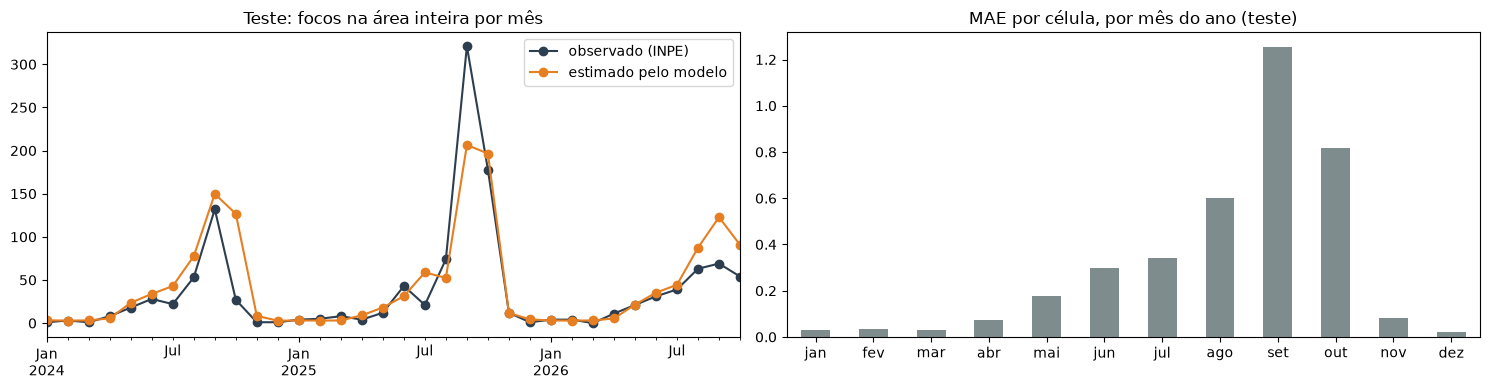

Leitura: o erro cresce na estação seca, quando a contagem é maior e varia mais entre anos.


In [11]:
reg = (teste.assign(previsto=pred_teste).groupby("data")[["focos", "previsto"]].sum())
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
reg["focos"].plot(ax=ax[0], marker="o", label="observado (INPE)", color="#2c3e50")
reg["previsto"].plot(ax=ax[0], marker="o", label="estimado pelo modelo", color="#e67e22")
ax[0].set_title("Teste: focos na área inteira por mês"); ax[0].legend(); ax[0].set_xlabel("")

erro_mes = (teste.assign(erro=np.abs(teste["focos"] - pred_teste))
                 .groupby("mes_do_ano")["erro"].mean().reindex(range(1, 13)))
erro_mes.plot(kind="bar", ax=ax[1], color="#7f8c8d")
ax[1].set_xticklabels(nomes_mes, rotation=0); ax[1].set_xlabel("")
ax[1].set_title("MAE por célula, por mês do ano (teste)")
plt.tight_layout(); plt.show()
print("Leitura: o erro cresce na estação seca, quando a contagem é maior e varia mais entre anos.")

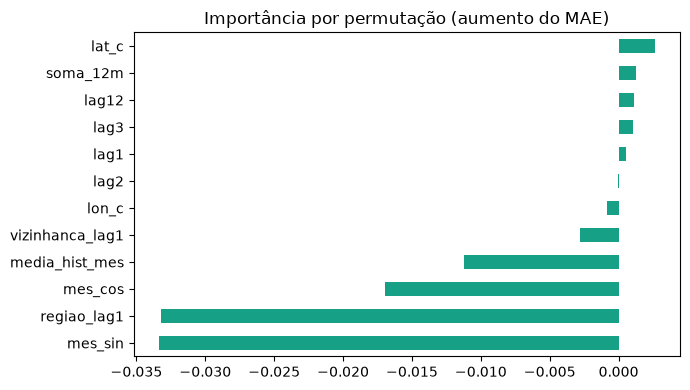

In [12]:
imp = permutation_importance(modelo, teste[FEATURES], teste["focos"], n_repeats=5,
                             random_state=SEMENTE, scoring="neg_mean_absolute_error")
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4), color="#16a085", title="Importância por permutação (aumento do MAE)")
plt.tight_layout(); plt.show()

## 5. Integração na solução

1. O modelo final é retreinado com **todo** o histórico.
2. Ele estima o próximo mês para cada célula e grava `saida/previsoes_proximo_mes.csv`.
3. As previsões do teste ficam em `saida/teste_previsoes.csv`, para calcular o erro histórico **da área escolhida**, e não só da região inteira.
4. A função `estimar_area` (célula abaixo) recebe o polígono do usuário, soma as células que ele cobre (ponderadas pela fração de área) e devolve o número com o aviso de estimativa experimental.
5. A tela de diagnóstico mostra esse valor em um bloco separado dos indicadores, com o rótulo **"Estimativa experimental"**, a margem de erro e o aviso.

_Opcional: se o backend do piloto estiver rodando, a mesma função pode virar uma rota (`GET /areas/{id}/estimativa-focos`) sem nenhuma mudança._

In [13]:
modelo_final = novos_modelos()[melhor]
modelo_final.fit(base[FEATURES], base["focos"])

# Linha de features para o mês seguinte ao último mês completo
proximo = ultimo_mes + 1
futuro = painel[["lin", "col", "celula", "lat_c", "lon_c"]].drop_duplicates().assign(mes=proximo, focos=np.nan)
completo = montar_features(pd.concat([painel, futuro], ignore_index=True))
x_futuro = completo[completo["mes"] == proximo].copy()
x_futuro["focos_estimados"] = np.clip(modelo_final.predict(x_futuro[FEATURES]), 0, None)

prev = x_futuro[["celula", "lin", "col", "lat_c", "lon_c", "focos_estimados"]].copy()
prev["mes_referencia"] = str(proximo)
prev.to_csv(os.path.join(PASTA_SAIDA, "previsoes_proximo_mes.csv"), index=False)

teste_out = teste[["celula", "mes", "focos"]].assign(previsto=pred_teste)
teste_out["mes"] = teste_out["mes"].astype(str)
teste_out.to_csv(os.path.join(PASTA_SAIDA, "teste_previsoes.csv"), index=False)

joblib.dump({"modelo": modelo_final, "features": FEATURES}, os.path.join(PASTA_SAIDA, "modelo_focos.joblib"))

metadados = {
    "gerado_em": datetime.now().isoformat(timespec="seconds"),
    "origem_dados": ORIGEM_DADOS,
    "satelite": SATELITE_REFERENCIA,
    "periodo_historico": f"{base['mes'].min()} a {ultimo_mes}",
    "mes_referencia": str(proximo),
    "grade": {"lat_min": LAT_MIN, "lat_max": LAT_MAX, "lon_min": LON_MIN, "lon_max": LON_MAX,
              "tamanho_celula_graus": TAMANHO_CELULA},
    "modelo": melhor,
    "metricas_teste": tabela_teste.loc[melhor].to_dict(),
    "metricas_baseline_sazonal": tabela_teste.loc["Baseline sazonal"].to_dict(),
    "periodo_teste": f"{teste['mes'].min()} a {teste['mes'].max()}",
    "aviso": ("Estimativa experimental baseada apenas no histórico de focos de calor do satélite de referência "
              "do INPE. Não classifica risco, não indica áreas aptas ou seguras para queima e não substitui "
              "avaliação de campo, profissionais habilitados, licenças ou protocolos oficiais."),
}
with open(os.path.join(PASTA_SAIDA, "metadados.json"), "w", encoding="utf-8") as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print("Mês estimado:", proximo, "| total estimado na grade:", round(prev["focos_estimados"].sum(), 1))
print("Arquivos gerados:", sorted(os.listdir(PASTA_SAIDA)))

Mês estimado: 2026-11 | total estimado na grade: 7.5
Arquivos gerados: ['.gitkeep', 'metadados.json', 'modelo_focos.joblib', 'previsoes_proximo_mes.csv', 'teste_previsoes.csv']


In [14]:
# ---- Função de integração: estimativa para uma área (polígono) ------------
# Recebe a área escolhida no mapa e devolve o bloco "Estimativa experimental"
# que aparece na tela de diagnóstico do Fire Intelligence.
from functools import lru_cache
from shapely.geometry import box, shape


@lru_cache(maxsize=4)
def _carregar(pasta_saida: str):
    with open(os.path.join(pasta_saida, "metadados.json"), encoding="utf-8") as f:
        meta = json.load(f)
    prev = pd.read_csv(os.path.join(pasta_saida, "previsoes_proximo_mes.csv"))
    teste = pd.read_csv(os.path.join(pasta_saida, "teste_previsoes.csv"))
    g = meta["grade"]
    t = g["tamanho_celula_graus"]
    prev["geom"] = [box(g["lon_min"] + c * t, g["lat_min"] + l * t,
                        g["lon_min"] + (c + 1) * t, g["lat_min"] + (l + 1) * t)
                    for l, c in zip(prev["lin"], prev["col"])]
    return meta, prev, teste


def estimar_area(geometria_geojson: dict, pasta_saida: str = "saida") -> dict:
    """Estimativa de focos para o polígono, com erro histórico calculado para a mesma área."""
    meta, prev, teste = _carregar(pasta_saida)
    area = shape(geometria_geojson)
    if area.is_empty or not area.is_valid:
        return {"situacao": "geometria_invalida", "mensagem": "O polígono enviado não é válido."}

    # fração de cada célula coberta pelo polígono
    fracao = prev["geom"].apply(lambda c: c.intersection(area).area / c.area)
    cob = prev.assign(fracao=fracao)[fracao > 0]
    if cob.empty:
        return {"situacao": "sem_dados_suficientes",
                "mensagem": "O polígono está fora da grade em que o modelo foi treinado.",
                "aviso": meta["aviso"]}

    estimado = float((cob["focos_estimados"] * cob["fracao"]).sum())

    # erro histórico (MAE) do modelo nesta mesma área, no período de teste
    t = teste.merge(cob[["celula", "fracao"]], on="celula")
    por_mes = (t.assign(y=t["focos"] * t["fracao"], p=t["previsto"] * t["fracao"])
                .groupby("mes")[["y", "p"]].sum())
    mae_area = float((por_mes["y"] - por_mes["p"]).abs().mean())

    return {
        "situacao": "ok",
        "tipo": "estimativa_experimental",
        "indicador": "Focos de calor estimados para o próximo mês",
        "mes_referencia": meta["mes_referencia"],
        "valor": round(estimado, 1),
        "unidade": "focos (satélite de referência)",
        "margem_erro_historica": round(mae_area, 1),
        "margem_erro_descricao": f"Erro médio absoluto do modelo nesta área em {meta['periodo_teste']}",
        "celulas_consideradas": int(len(cob)),
        "metodo": f"{meta['modelo']} treinado com o histórico mensal de focos por célula de "
                  f"{meta['grade']['tamanho_celula_graus']}° ({meta['periodo_historico']}).",
        "fonte": meta["origem_dados"],
        "satelite": meta["satelite"],
        "gerado_em": meta["gerado_em"],
        "aviso": meta["aviso"],
    }

In [15]:
# ---- Demonstração: estimativa para uma área escolhida no mapa --------------

# Polígono de exemplo (retângulo em torno de Alto Paraíso de Goiás).
# É o mesmo formato GeoJSON que a tela de mapa do Fire Intelligence usa para a área de estudo.
poligono_exemplo = {"type": "Polygon", "coordinates": [[
    [-47.70, -14.30], [-47.35, -14.30], [-47.35, -13.95], [-47.70, -13.95], [-47.70, -14.30]]]}

resposta = estimar_area(poligono_exemplo, pasta_saida=PASTA_SAIDA)
print(json.dumps(resposta, ensure_ascii=False, indent=2))

{
  "situacao": "ok",
  "tipo": "estimativa_experimental",
  "indicador": "Focos de calor estimados para o próximo mês",
  "mes_referencia": "2026-11",
  "valor": 0.5,
  "unidade": "focos (satélite de referência)",
  "margem_erro_historica": 2.4,
  "margem_erro_descricao": "Erro médio absoluto do modelo nesta área em 2024-01 a 2026-10",
  "celulas_consideradas": 20,
  "metodo": "Gradient Boosting (Poisson) treinado com o histórico mensal de focos por célula de 0.1° (2013-01 a 2026-10).",
  "fonte": "INPE, Programa Queimadas: focos_chapada_2012_2026.csv",
  "satelite": "AQUA_M-T",
  "gerado_em": "2026-11-19T18:37:59",
  "aviso": "Estimativa experimental baseada apenas no histórico de focos de calor do satélite de referência do INPE. Não classifica risco, não indica áreas aptas ou seguras para queima e não substitui avaliação de campo, profissionais habilitados, licenças ou protocolos oficiais."
}


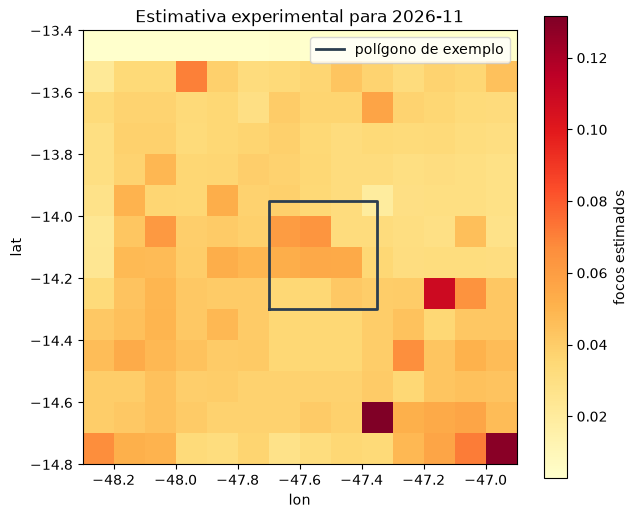

In [16]:
# Mapa das estimativas por célula (o mesmo dado que o frontend pode desenhar no Leaflet)
m = prev.pivot(index="lin", columns="col", values="focos_estimados").sort_index()
plt.figure(figsize=(7, 6))
plt.imshow(m.values, origin="lower", cmap="YlOrRd",
           extent=[LON_MIN, LON_MIN + m.shape[1] * TAMANHO_CELULA, LAT_MIN, LAT_MIN + m.shape[0] * TAMANHO_CELULA])
plt.colorbar(label="focos estimados")
xs, ys = zip(*poligono_exemplo["coordinates"][0]); plt.plot(xs, ys, color="#2c3e50", lw=2, label="polígono de exemplo")
plt.title(f"Estimativa experimental para {proximo}"); plt.legend(); plt.xlabel("lon"); plt.ylabel("lat")
plt.show()

## 6. Limitações e próximos passos

**Limitações (exibir também na interface).**
- Foco de calor é uma detecção por satélite. Não é incêndio, não mede área queimada e pode incluir falsos positivos.
- Um único satélite (o de referência) detecta só parte dos focos. A estimativa vale para **esse satélite**, não para o total real. Se o satélite de referência mudar no período, a série precisa ser tratada antes de treinar.
- A localização de cada foco tem imprecisão de cerca de 1 km, por isso a grade é de ~11 km.
- O modelo usa só o histórico. Um ano atipicamente seco ou úmido gera erro maior, como mostra o gráfico de erro por mês.
- Os erros mostrados vêm do período de teste. Não há garantia de que se mantenham.

**Próximos passos.**
- Incluir chuva acumulada e dias sem chuva (CHIRPS ou INMET) e a cobertura da terra do MapBiomas por célula.
- Usar as leituras da estação ambiental (disciplina de Physical Computing) quando houver dados reais de campo.
- Intervalo de previsão com regressão quantílica, em vez de só o MAE histórico.